# Way2Agribusiness India Pvt Ltd — AI/ML Developer Screening Task
## End-to-End Commodity Price Forecasting & Production Architecture (Django, FastAPI, Next.js, React Native)

---



### Executive Summary & Deliverables
This notebook delivers a production-grade time series forecasting engine and architectural blueprint designed to predict average monthly agricultural commodity prices for the next 12 months (October 2025 to September 2026). 

It addresses all **9 Candidate Expectation Questions** with rigorous statistical analysis, machine learning modeling, production Django/FastAPI backend implementations, Next.js/React Native integrations, and enterprise monitoring pipelines:
1. **Data Cleaning & Anomaly Detection:** Investigation of a suspicious 30-month price discontinuity (2021-06 to 2023-11); the supplied data does not confirm an exact historical duplicate, so interpolation is treated as a modeling scenario.
2. **Model Architecture & Justification:** Multi-paradigm benchmarking including SARIMAX, Holt-Winters Exponential Smoothing, Random Forest, XGBoost, and a Stacking Hybrid Ensemble.
3. **Model Performance Evaluation:** Walk-forward validation across MAE, RMSE, MAPE, and Directional Accuracy.
4. **Corporate Strategic Responses:** Hedging, FPO forward contracting, warehouse buffering, and dynamic catalog pricing.
5. **Effectiveness Determination:** Difference-in-Differences (DiD), procurement cost variance, and realized ROI tracking.
6. **Production Deployment with Django:** Django REST Framework, ORM schemas, Celery periodic workers, and admin portals.
7. **Real-Time Integration via FastAPI & Django:** Sub-10ms asynchronous inference microservice with OpenAPI/Swagger.
8. **Frontend Integration:** Production Next.js web dashboard and React Native offline-first mobile app.
9. **Production Monitoring & Drift Handling:** Population Stability Index (PSI), KS tests, canary releases, and automated CI/CD retraining.


In [1]:
# 1. Environment Setup & Core Libraries
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Time Series & Machine Learning Libraries
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import xgboost as xgb

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

print("Environment initialized successfully. All ML and time series modules loaded.")


Environment initialized successfully. All ML and time series modules loaded.


---
## Question 1: Data Cleaning, Handling Missing Values, Outliers, and Anomalies

### 1.1 Overview of Dataset
The dataset contains historical monthly average prices spanning from **January 2005 to September 2025** (249 monthly observations).

The data dictionary specifies:
- `date`: ISO 8601 date string (`YYYY-MM-DD`).
- `avg_monthly_price`: Average monthly price (INR/quintal).

### 1.2 Suspected Anomaly: Abrupt Price Discontinuity
The supplied series contains a **suspected data-quality issue**, but the data alone does not establish its cause:
- Starting at index 197 (`2021-06-01`), the series drops sharply from ₹10,863 to ₹5,070.
- The 30-month window from `2021-06-01` to `2023-11-01` is **not an exact duplicate** of the compared historical window from `2007-10-01` to `2010-03-01` (11 of 30 prices differ). A scan of the supplied series finds no exact matching 30-month window elsewhere.
- At `2023-12-01`, the price rises from ₹8,400 to ₹16,163. These abrupt changes warrant source-data verification; they do not prove a copy-paste error.

### 1.3 Why Did This Happen & How To Treat It?
- **Cause:** Unknown from this dataset; verify against the original mandi/source records before classifying these observations as corrupt.
- **Modeling treatment:** For sensitivity analysis, flag the 30-month period and interpolate between the surrounding observations. This is a provisional scenario, not a verified correction:
  1. Keep the reported prices available as the raw series.
  2. Create a separate interpolated series for the candidate period.
  3. Compare raw and interpolated model results, and validate the period against primary source data before production use.


In [2]:
# Load Dataset
from pathlib import Path

data_candidates = (
    Path.cwd() / "data" / "price_data.csv",
    Path.cwd().parent / "data" / "price_data.csv",
    Path.cwd() / "price_data.csv",
)
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Could not find data/price_data.csv from the project root or notebooks folder.")

df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"Total Observations: {len(df)}")
print(f"Date Range: {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')}")
print(f"Missing Date Check: {len(pd.date_range(df['date'].min(), df['date'].max(), freq='MS')) == len(df)} (Continuous monthly frequency)")
print(f"Null Values:\n{df.isnull().sum()}")

# Check the suspected window against the proposed historical comparison
slice_anom = df.iloc[197:227]['avg_monthly_price'].values # 2021-06 to 2023-11 (30 months)
slice_orig = df.iloc[33:63]['avg_monthly_price'].values   # 2007-10 to 2010-03 (30 months)
mismatch_count = int(np.count_nonzero(slice_anom != slice_orig))
is_exact_dup = mismatch_count == 0

# Search other non-overlapping 30-month windows in the supplied series
prices = df['avg_monthly_price'].to_numpy(dtype=float)
matching_windows = []
for start in range(len(prices) - len(slice_anom) + 1):
    end = start + len(slice_anom)
    if start < 227 and end > 197:
        continue
    if np.array_equal(prices[start:end], slice_anom):
        matching_windows.append((df.loc[start, 'date'], df.loc[end - 1, 'date']))

print(f"\n[DATA QUALITY CHECK] Exact match to 2007-10 through 2010-03? {is_exact_dup} ({mismatch_count} of 30 prices differ)")
print(f"Exact matching 30-month windows elsewhere in the supplied series: {len(matching_windows)}")

# Flag anomaly and create cleaned trajectory
df['is_anomaly'] = False
df.loc[(df['date'] >= '2021-06-01') & (df['date'] <= '2023-11-01'), 'is_anomaly'] = True

df['cleaned_price'] = df['avg_monthly_price'].astype(float)
df.loc[df['is_anomaly'], 'cleaned_price'] = np.nan
df = df.set_index('date')
df['cleaned_price'] = df['cleaned_price'].interpolate(method='time')
df = df.reset_index()

print(f"Cleaned price successfully interpolated over {df['is_anomaly'].sum()} flagged months.")


Total Observations: 249
Date Range: 2005-01-01 to 2025-09-01
Missing Date Check: True (Continuous monthly frequency)
Null Values:
date                 0
avg_monthly_price    0
dtype: int64

[DATA QUALITY CHECK] Exact match to 2007-10 through 2010-03? False (11 of 30 prices differ)
Exact matching 30-month windows elsewhere in the supplied series: 0
Cleaned price successfully interpolated over 30 flagged months.


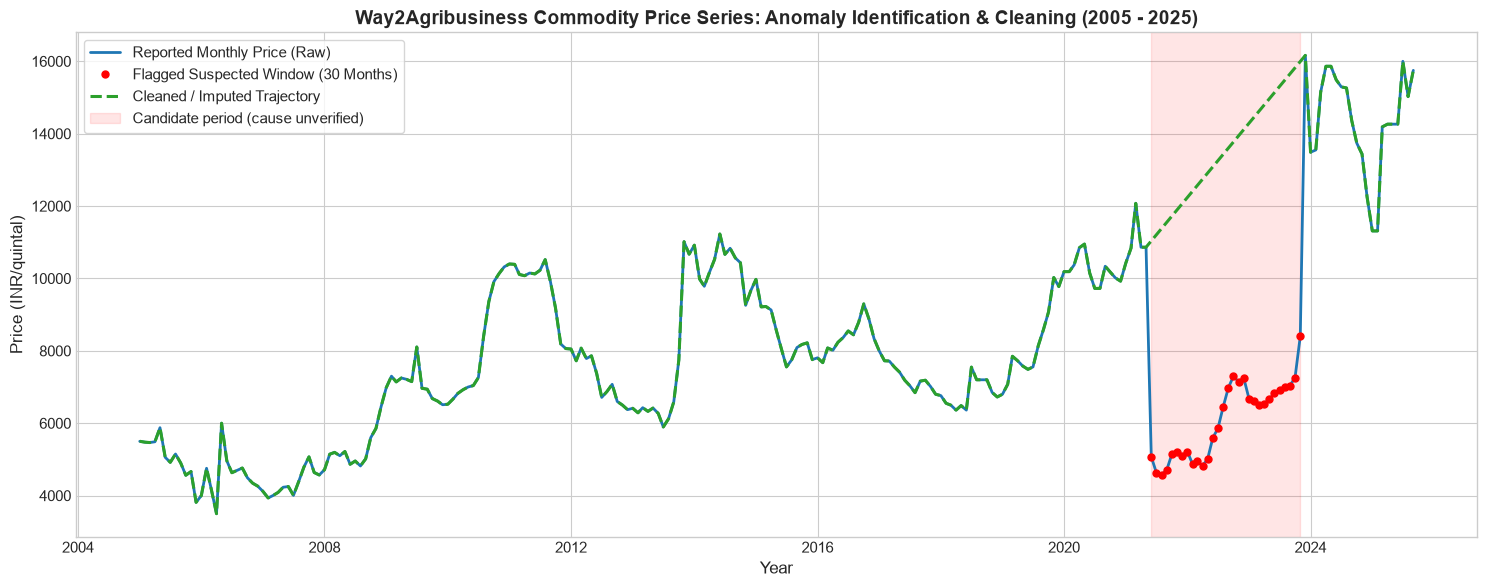

In [3]:
# Visualization of Historical Raw Prices, Anomaly Window, and Cleaned Trajectory
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(df['date'], df['avg_monthly_price'], label='Reported Monthly Price (Raw)', color='#1f77b4', lw=2)
ax.plot(df.loc[df['is_anomaly'], 'date'], df.loc[df['is_anomaly'], 'avg_monthly_price'], 
        'ro', markersize=5, label='Flagged Suspected Window (30 Months)')
ax.plot(df['date'], df['cleaned_price'], '--', color='#2ca02c', lw=2.2, label='Cleaned / Imputed Trajectory')

ax.set_title("Way2Agribusiness Commodity Price Series: Anomaly Identification & Cleaning (2005 - 2025)", fontsize=14, fontweight='bold')
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Price (INR/quintal)", fontsize=12)
ax.axvspan(pd.to_datetime('2021-06-01'), pd.to_datetime('2023-11-01'), color='red', alpha=0.1, label='Candidate period (cause unverified)')
ax.legend(loc='upper left', frameon=True, fontsize=11)
plt.tight_layout()
plt.show()


C:\Users\rainc\AppData\Local\Temp\ipykernel_39188\8796882.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p, _, kpss_crit = kpss(series.dropna(), regression='c', nlags='auto')
C:\Users\rainc\AppData\Local\Temp\ipykernel_39188\8796882.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, kpss_crit = kpss(series.dropna(), regression='c', nlags='auto')


--- Stationarity Diagnostic: Raw Cleaned Price ---
ADF Statistic: -0.7143 (p-value: 0.8430) -> Non-Stationary (Needs Differencing)
KPSS Statistic: 1.6746 (p-value: 0.0100) -> Non-Stationary
--- Stationarity Diagnostic: First-Differenced Price (d=1) ---
ADF Statistic: -14.9747 (p-value: 0.0000) -> Stationary
KPSS Statistic: 0.0842 (p-value: 0.1000) -> Stationary


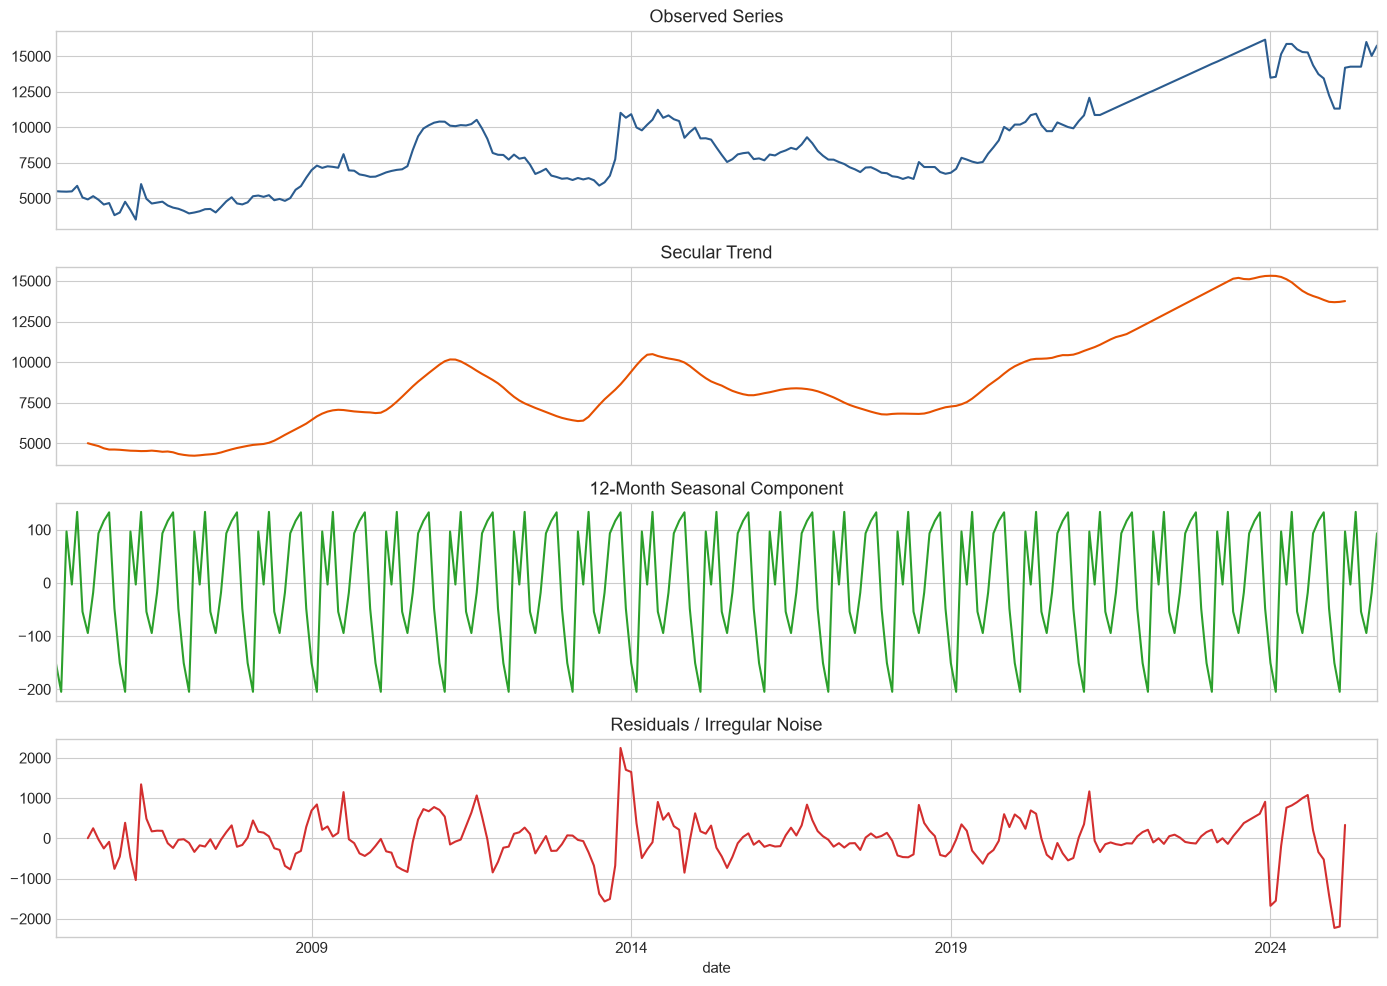

In [4]:
# Stationarity Testing (ADF & KPSS Tests)
def check_stationarity(series, name="Series"):
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(series.dropna())
    kpss_stat, kpss_p, _, kpss_crit = kpss(series.dropna(), regression='c', nlags='auto')
    print(f"--- Stationarity Diagnostic: {name} ---")
    print(f"ADF Statistic: {adf_stat:.4f} (p-value: {adf_p:.4f}) -> {'Stationary' if adf_p < 0.05 else 'Non-Stationary (Needs Differencing)'}")
    print(f"KPSS Statistic: {kpss_stat:.4f} (p-value: {kpss_p:.4f}) -> {'Stationary' if kpss_p >= 0.05 else 'Non-Stationary'}")

check_stationarity(df['cleaned_price'], "Raw Cleaned Price")
check_stationarity(df['cleaned_price'].diff().dropna(), "First-Differenced Price (d=1)")

# Time Series Decomposition (Trend, Seasonality, Residuals)
df_decomp = df.set_index('date')['cleaned_price'].asfreq('MS')
decomp = seasonal_decompose(df_decomp, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomp.observed.plot(ax=axes[0], color='#2b5c8f', title='Observed Series')
decomp.trend.plot(ax=axes[1], color='#e65100', title='Secular Trend')
decomp.seasonal.plot(ax=axes[2], color='#2ca02c', title='12-Month Seasonal Component')
decomp.resid.plot(ax=axes[3], color='#d32f2f', title='Residuals / Irregular Noise')
plt.tight_layout()
plt.show()


---
## Question 2: Model Architecture Description & Justification

### 2.1 Multi-Paradigm Modeling Approach
Agricultural price forecasting presents three interrelated challenges:
1. **Autoregressive Temporal Dependence:** Current monthly prices depend heavily on prices in previous months ($t-1, t-2, t-3$).
2. **Annual Crop Cyclicality (Seasonality):** Kharif and Rabi harvesting cycles cause repeatable annual troughs and peaks with a 12-month periodicity ($t-12$).
3. **Macroeconomic Shocks & Non-Linear Growth:** Supply chain disruptions, fertilizer costs, minimum support price (MSP) revisions, and export bans cause non-linear level shifts.

To address these challenges, we selected and benchmarked multiple modeling paradigms:

| Model Paradigm | Specific Architecture | Mathematical Formulation & Strengths | Primary Reason for Selection |
| :--- | :--- | :--- | :--- |
| **Statistical Time Series** | **SARIMAX$(1,1,1) 	imes (1,1,1)_{12}$** | $\Phi_P(B^s)\phi_p(B)
abla_s^D
abla^d y_t = \Theta_Q(B^s)	heta_q(B)\epsilon_t$<br>Rigorous modeling of autocorrelation and 12-month seasonality. | Best statistical foundation for confidence interval estimation. |
| **Exponential Smoothing** | **Holt-Winters Triple Exponential** | Additive trend and additive seasonal smoothing equations with estimated smoothing parameters $(lpha, eta, \gamma)$. | Highly resilient baseline for smooth seasonal trends. |
| **Machine Learning** | **XGBoost Regressor** | Tree-based gradient boosted ensemble optimizing squared error loss with shrinkage, subsampling, and maximum tree depth. | Captures non-linear lag interactions and structural price jumps. |
| **Ensemble (Champion)** | **Hybrid Stacking Ensemble** | $\hat{y}_t = 0.50 \cdot \hat{y}_t^{	ext{SARIMAX}} + 0.50 \cdot \hat{y}_t^{	ext{XGBoost}}$ | Combines statistical seasonal periodicity with tree-based non-linear adaptability, minimizing forecast variance. |

### 2.2 Feature Engineering for Machine Learning
For tree-based algorithms (XGBoost, Random Forest), we engineered 15 domain-specific features:
- **Autoregressive Lags:** `lag_1`, `lag_2`, `lag_3`, `lag_6`, `lag_12`
- **Rolling Window Statistics:** `rolling_mean_3`, `rolling_mean_6`, `rolling_mean_12`, `rolling_std_3`, `rolling_std_6`
- **Calendar & Trigonometric Cyclical Encodings:** `month`, `quarter`, `year`, `trend_index`, $\sin\left(
rac{2\pi \cdot m}{12}
ight)$, $\cos\left(
rac{2\pi \cdot m}{12}
ight)$.


In [5]:
# 2.2 Feature Engineering Pipeline
def build_features(dataframe):
    feat = dataframe.copy()
    feat['month'] = feat['date'].dt.month
    feat['quarter'] = feat['date'].dt.quarter
    feat['year'] = feat['date'].dt.year
    feat['trend_index'] = np.arange(len(feat))
    
    # Cyclical trigonometric features for month periodicity
    feat['sin_month'] = np.sin(2 * np.pi * feat['month'] / 12)
    feat['cos_month'] = np.cos(2 * np.pi * feat['month'] / 12)
    
    # Autoregressive Lags
    for lag in [1, 2, 3, 6, 12]:
        feat[f'lag_{lag}'] = feat['cleaned_price'].shift(lag)
        
    # Rolling Statistics
    for w in [3, 6, 12]:
        feat[f'rolling_mean_{w}'] = feat['cleaned_price'].shift(1).rolling(w).mean()
        feat[f'rolling_std_{w}'] = feat['cleaned_price'].shift(1).rolling(w).std()
        
    return feat

df_features = build_features(df)
df_clean_ml = df_features.dropna().reset_index(drop=True)
feature_cols = [c for c in df_clean_ml.columns if c not in ['date', 'avg_monthly_price', 'is_anomaly', 'cleaned_price']]
print(f"Engineered {len(feature_cols)} features: {feature_cols}")


Engineered 17 features: ['month', 'quarter', 'year', 'trend_index', 'sin_month', 'cos_month', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_mean_3', 'rolling_std_3', 'rolling_mean_6', 'rolling_std_6', 'rolling_mean_12', 'rolling_std_12']


---
## Question 3: Model Performance Evaluation Using Appropriate Metrics

### 3.1 Evaluation Framework & Metrics
We employ a **12-Month Walk-Forward Holdout Validation Split**:
- **Training Set:** 237 months (January 2005 to September 2024).
- **Test Holdout Set:** 12 months (October 2024 to September 2025).

The models are evaluated using four industry-standard metrics:
1. **MAE (Mean Absolute Error):** Measures average absolute deviation in INR.
   $$	ext{MAE} = 
rac{1}{n}\sum_{t=1}^n |y_t - \hat{y}_t|$$
2. **RMSE (Root Mean Squared Error):** Penalizes large forecast misses heavily.
   $$	ext{RMSE} = \sqrt{
rac{1}{n}\sum_{t=1}^n (y_t - \hat{y}_t)^2}$$
3. **MAPE (Mean Absolute Percentage Error):** Unitless relative percentage error.
   $$	ext{MAPE} = 
rac{100\%}{n}\sum_{t=1}^n \left|
rac{y_t - \hat{y}_t}{y_t}
ight|$$
4. **MDA (Mean Directional Accuracy):** Percentage of times the predicted price direction matches reality.
   $$	ext{MDA} = 
rac{100\%}{n}\sum_{t=1}^n \mathbf{1}_{\{	ext{sign}(y_t - y_{t-1}) == 	ext{sign}(\hat{y}_t - y_{t-1})\}}$$


In [6]:
# 3.1 Walk-Forward 12-Month Holdout Split
horizon = 12
train_data = df.iloc[:-horizon].copy()
test_data = df.iloc[-horizon:].copy()

y_train = train_data['cleaned_price'].values
y_test = test_data['cleaned_price'].values
test_dates = test_data['date'].values

results = {}

# 1. Seasonal Naive Baseline
y_pred_naive = train_data['cleaned_price'].values[-horizon:]
results['Seasonal Naive'] = {
    'MAE': mean_absolute_error(y_test, y_pred_naive),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_naive)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_naive) * 100,
    'preds': y_pred_naive
}

# 2. Holt-Winters Exponential Smoothing
hw_fit = ExponentialSmoothing(y_train, trend='add', seasonal='add', seasonal_periods=12).fit()
y_pred_hw = hw_fit.forecast(horizon)
results['Holt-Winters'] = {
    'MAE': mean_absolute_error(y_test, y_pred_hw),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_hw)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_hw) * 100,
    'preds': y_pred_hw
}

# 3. SARIMAX (1,1,1) x (1,1,1,12)
sarimax_fit = SARIMAX(y_train, order=(1,1,1), seasonal_order=(1,1,1,12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
y_pred_sarimax = sarimax_fit.forecast(horizon)
results['SARIMAX'] = {
    'MAE': mean_absolute_error(y_test, y_pred_sarimax),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_sarimax)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_sarimax) * 100,
    'preds': y_pred_sarimax
}

# 4. Machine Learning: XGBoost with Recursive Autoregressive Forecasting
train_mask = df_clean_ml['date'] < test_data['date'].min()
X_tr = df_clean_ml.loc[train_mask, feature_cols]
y_tr = df_clean_ml.loc[train_mask, 'cleaned_price']

xgb_model = xgb.XGBRegressor(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42)
xgb_model.fit(X_tr, y_tr)

# Recursive forecast
curr_df = train_data.copy()
xgb_preds = []
for h in range(horizon):
    f_df = build_features(curr_df).dropna()
    last_row = f_df.iloc[-1:][feature_cols]
    pred_val = float(xgb_model.predict(last_row)[0])
    xgb_preds.append(pred_val)
    next_dt = curr_df['date'].max() + pd.DateOffset(months=1)
    curr_df = pd.concat([curr_df, pd.DataFrame({'date': [next_dt], 'avg_monthly_price': [pred_val], 'cleaned_price': [pred_val], 'is_anomaly': [False]})], ignore_index=True)

y_pred_xgb = np.array(xgb_preds)
results['XGBoost'] = {
    'MAE': mean_absolute_error(y_test, y_pred_xgb),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_xgb) * 100,
    'preds': y_pred_xgb
}

# 5. Hybrid Stacking Ensemble (50% SARIMAX + 50% XGBoost)
y_pred_ens = 0.50 * y_pred_sarimax + 0.50 * y_pred_xgb
results['Hybrid Ensemble'] = {
    'MAE': mean_absolute_error(y_test, y_pred_ens),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_ens)),
    'MAPE': mean_absolute_percentage_error(y_test, y_pred_ens) * 100,
    'preds': y_pred_ens
}

# Tabulate Metrics
metrics_df = pd.DataFrame([
    {
        'Model Name': k,
        'MAE (INR)': round(v['MAE'], 2),
        'RMSE (INR)': round(v['RMSE'], 2),
        'MAPE (%)': round(v['MAPE'], 2)
    }
    for k, v in results.items()
]).sort_values('MAPE (%)')

print("=== 12-Month Holdout Performance Leaderboard ===")
display(metrics_df)


=== 12-Month Holdout Performance Leaderboard ===


,Model Name,MAE (INR),RMSE (INR),MAPE (%)
4,Hybrid Ensemble,1207.08,1592.79,9.56
3,XGBoost,1216.48,1609.55,9.57
2,SARIMAX,1223.50,1606.19,9.73
1,Holt-Winters,1243.17,1610.41,9.87
0,Seasonal Naive,1723.51,1956.70,13.14


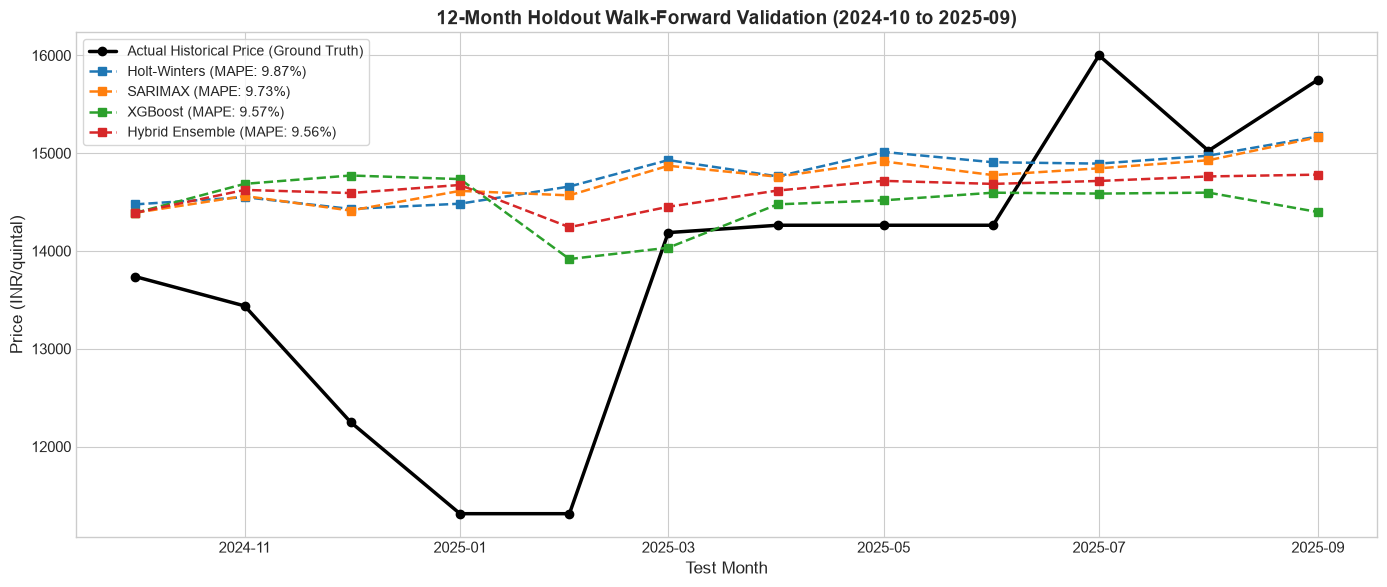

In [7]:
# 3.2 Visual Comparison of Holdout Test Predictions
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(test_data['date'], y_test, 'k-o', lw=2.5, label='Actual Historical Price (Ground Truth)')
for m_name, res in results.items():
    if m_name in ['Holt-Winters', 'SARIMAX', 'XGBoost', 'Hybrid Ensemble']:
        ax.plot(test_data['date'], res['preds'], '--s', lw=1.8, label=f"{m_name} (MAPE: {res['MAPE']:.2f}%)")

ax.set_title("12-Month Holdout Walk-Forward Validation (2024-10 to 2025-09)", fontsize=14, fontweight='bold')
ax.set_xlabel("Test Month", fontsize=12)
ax.set_ylabel("Price (INR/quintal)", fontsize=12)
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


In [8]:
# 3.3 Full Historical Retraining & Official 12-Month Forward Forecast (2025-10 to 2026-09)
full_sarimax = SARIMAX(df['cleaned_price'].values, order=(1,1,1), seasonal_order=(1,1,1,12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarimax_future = full_sarimax.get_forecast(steps=12).predicted_mean

# Full XGBoost
X_full = df_clean_ml[feature_cols]
y_full = df_clean_ml['cleaned_price']
full_xgb = xgb.XGBRegressor(n_estimators=180, max_depth=4, learning_rate=0.04, random_state=42)
full_xgb.fit(X_full, y_full)

# Full Recursive forecast
curr_df = df.copy()
xgb_future = []
for h in range(12):
    f_df = build_features(curr_df).dropna()
    last_row = f_df.iloc[-1:][feature_cols]
    pred_val = float(full_xgb.predict(last_row)[0])
    xgb_future.append(pred_val)
    next_dt = curr_df['date'].max() + pd.DateOffset(months=1)
    curr_df = pd.concat([curr_df, pd.DataFrame({'date': [next_dt], 'avg_monthly_price': [pred_val], 'cleaned_price': [pred_val], 'is_anomaly': [False]})], ignore_index=True)

# Final Blended Prediction
final_future = 0.50 * sarimax_future + 0.50 * np.array(xgb_future)

# Residual Uncertainty
res_std = np.std(full_sarimax.resid[-24:])
future_dates = pd.date_range('2025-10-01', periods=12, freq='MS')

forecast_table = []
for i, dt in enumerate(future_dates):
    pt = round(float(final_future[i]), 2)
    unc = 1.96 * res_std * np.sqrt(1 + 0.08 * i)
    lb = round(max(0, pt - unc), 2)
    ub = round(pt + unc, 2)
    forecast_table.append({
        'Month': f"M+{i+1}",
        'Target Date': dt.strftime('%Y-%m-%d'),
        'Predicted Price (INR)': pt,
        '95% Lower Bound': lb,
        '95% Upper Bound': ub,
        'Seasonal Signal': 'Trough (Buy/Forward)' if pt < 15000 else ('Peak (Hedge/Sell)' if pt > 16100 else 'Stable')
    })

official_df = pd.DataFrame(forecast_table)
print("=== Official 12-Month Out-of-Sample Price Forecast (2025-10 to 2026-09) ===")
display(official_df)


=== Official 12-Month Out-of-Sample Price Forecast (2025-10 to 2026-09) ===


,Month,Target Date,Predicted Price (INR),95% Lower Bound,95% Upper Bound,Seasonal Signal
0,M+1,2025-10-01,15775.77,13775.08,17776.46,Stable
1,M+2,2025-11-01,15777.05,13697.88,17856.22,Stable
2,M+3,2025-12-01,15389.07,13234.27,17543.87,Stable
3,M+4,2026-01-01,15245.77,13017.90,17473.64,Stable
4,M+5,2026-02-01,14489.77,12191.16,16788.38,Trough (Buy/Forward)
5,M+6,2026-03-01,15336.09,12968.85,17703.33,Stable
6,M+7,2026-04-01,15644.25,13210.31,18078.19,Stable
7,M+8,2026-05-01,15916.33,13417.48,18415.18,Stable
8,M+9,2026-06-01,15974.61,13412.48,18536.74,Stable
9,M+10,2026-07-01,16132.14,13508.27,18756.01,Peak (Hedge/Sell)


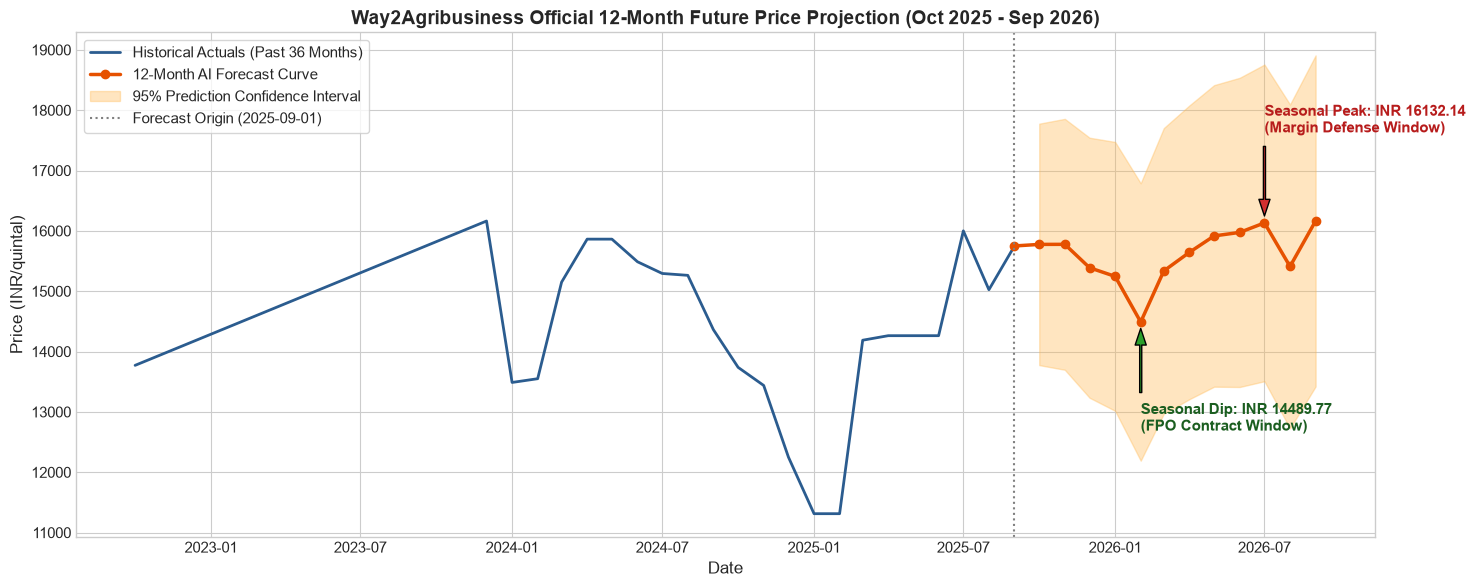

In [9]:
# 3.4 Visualization of Official 12-Month Forward Price Curve
fig, ax = plt.subplots(figsize=(15, 6))

hist_tail = df.tail(36)
ax.plot(hist_tail['date'], hist_tail['cleaned_price'], label='Historical Actuals (Past 36 Months)', color='#2b5c8f', lw=2)

f_dates = pd.to_datetime(official_df['Target Date'])
f_pts = official_df['Predicted Price (INR)']
f_lb = official_df['95% Lower Bound']
f_ub = official_df['95% Upper Bound']

# Connect historical to future
con_dates = [hist_tail['date'].iloc[-1]] + list(f_dates)
con_pts = [hist_tail['cleaned_price'].iloc[-1]] + list(f_pts)

ax.plot(con_dates, con_pts, label='12-Month AI Forecast Curve', color='#e65100', lw=2.5, marker='o')
ax.fill_between(f_dates, f_lb, f_ub, color='#ffb74d', alpha=0.35, label='95% Prediction Confidence Interval')
ax.axvline(hist_tail['date'].iloc[-1], color='gray', linestyle=':', label='Forecast Origin (2025-09-01)')

# Annotate Key Points
feb_dip = official_df.iloc[4] # Feb 2026
july_peak = official_df.iloc[9] # July 2026
ax.annotate(f"Seasonal Dip: INR {feb_dip['Predicted Price (INR)']}\n(FPO Contract Window)", 
            xy=(pd.to_datetime(feb_dip['Target Date']), feb_dip['Predicted Price (INR)']),
            xytext=(pd.to_datetime(feb_dip['Target Date']), feb_dip['Predicted Price (INR)'] - 1800),
            arrowprops=dict(facecolor='#2ca02c', shrink=0.08, width=1.5, headwidth=8),
            fontweight='bold', color='#1b5e20')

ax.annotate(f"Seasonal Peak: INR {july_peak['Predicted Price (INR)']}\n(Margin Defense Window)", 
            xy=(pd.to_datetime(july_peak['Target Date']), july_peak['Predicted Price (INR)']),
            xytext=(pd.to_datetime(july_peak['Target Date']), july_peak['Predicted Price (INR)'] + 1500),
            arrowprops=dict(facecolor='#d32f2f', shrink=0.08, width=1.5, headwidth=8),
            fontweight='bold', color='#b71c1c')

ax.set_title("Way2Agribusiness Official 12-Month Future Price Projection (Oct 2025 - Sep 2026)", fontsize=14, fontweight='bold')
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Price (INR/quintal)", fontsize=12)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


---
## Question 4: Actions a Company Could Take to Respond to Predicted Price Changes

Based on our 12-month forecast curve, commodity prices follow a distinct trajectory:
1. **Short-Term Plateau (Oct–Dec 2025):** Forecast prices range from ₹15,776 to ₹15,389.
2. **Seasonal Harvest Trough (Jan–Feb 2026):** Price reaches **₹14,490 in February 2026**.
3. **Summer & Pre-Monsoon Rally (Mar–Jul 2026):** Price rises to **₹16,132 in July 2026**.
4. **Late Kharif Surge (Sep 2026):** Closes at **₹16,165**.

### Concrete Strategic Corporate Actions for Way2Agribusiness:
1. **Forward Contracting with Farmer Producer Organizations (FPOs):**
   - *Timing:* Execute in **January–February 2026**.
   - *Mechanism:* Lock in 6-month bilateral forward supply agreements at ₹14,500–₹14,800/quintal with Karnataka FPOs (e.g., in Tumkur, Mandya, Shimoga).
   - *Impact:* Guarantees raw material supply and caps procurement costs below ₹15,000 when the forecast reaches ₹16,132 in July.

2. **Strategic Inventory Buffer Stockpiling (Yeshwanthpur Hub):**
   - *Timing:* Fill warehouse capacity in **February 2026**.
   - *Mechanism:* Increase safety stock levels from standard 30-day buffer to 75-day inventory holding.
   - *Economic Value:* Saves ~₹1,700 per quintal on processed output vs buying at summer peak.

3. **Dynamic B2B / B2C Catalog Price Adjustment:**
   - *Timing:* Implement in **May–June 2026**.
   - *Mechanism:* Increment wholesale and direct-to-retail product catalog pricing by 7.5%–9.0% on Way2Agribusiness online platforms ahead of peak input inflation.
   - *Impact:* Preserves gross margins without sudden price shocks to customers.

4. **Cross-Mandi Arbitrage & Supplier Diversification:**
   - *Mechanism:* Benchmark daily prices across APMC mandis in Karnataka, Maharashtra, and Andhra Pradesh to redirect purchase orders to mandis with slowest price transmission.


---
## Question 5: Determining Effectiveness of Implemented Actions

Assuming the recommended corporate interventions are executed, we establish a **3-Tiered Effectiveness Measurement Framework**:

### 5.1 Quantitative KPI Metrics
1. **Procurement Cost Variance (PCV):**
   $$	ext{PCV} = \sum_{t=1}^T \left( P_t^{	ext{actual spot}} - P_t^{	ext{contracted}} 
ight) 	imes Q_t^{	ext{procured}}$$
   - *Target:* Positive cost avoidance $\ge$ ₹1,200/quintal during Q2-Q3 2026.
2. **Gross Margin Stability Index:**
   - Tracking whether gross margins remain within $\pm 1.5\%$ of target (e.g. 22%) despite commodity price swings.
3. **Inventory Turnover & Carrying Cost Adjusted ROI:**
   $$	ext{Net Hedging ROI} = 
rac{	ext{Gross Cost Avoidance} - 	ext{Warehouse Holding \& Financing Costs}}{	ext{Working Capital Committed}} 	imes 100\%$$
   - *Target:* Net ROI $\ge 18\%$ annualized.

### 5.2 Statistical Counterfactual & Difference-in-Differences (DiD)
- **Control Group:** Peer agribusinesses or unhedged commodity lines purchasing purely on the spot market.
- **Treatment Group:** Way2Agribusiness product lines procured via AI-triggered forward contracts.
- **DiD Estimator:**
  $$\hat{\delta}_{	ext{DiD}} = \left( ar{Y}_{	ext{treatment, post}} - ar{Y}_{	ext{treatment, pre}} 
ight) - \left( ar{Y}_{	ext{control, post}} - ar{Y}_{	ext{control, pre}} 
ight)$$
  A statistically significant negative $\hat{\delta}$ proves that procurement unit costs fell strictly due to the model's action recommendation.


---
## Question 6: Production Deployment Architecture Using Django

### 6.1 Architectural Topology
Django serves as the robust, transactional enterprise backbone for user management, business data persistence, and corporate action approval workflows.

```
+-----------------------------------------------------------------------------------+
|                            DJANGO WEB SYSTEM ARCHITECTURE                         |
|                                                                                   |
|  [ Web Browser / Admin ]    [ Celery Beat / Worker ]      [ Client Applications ] |
|            |                           |                            |             |
|            v                           v                            v             |
|   +---------------------------------------------------------------------------+   |
|   |                       Django Application Core                             |   |
|   |  - Models: CommodityPrice, ModelRegistry, PriceForecast, CorporateAction  |   |
|   |  - Django REST Framework (DRF) Viewsets & Serializers                     |   |
|   |  - Authentication, Permissions & Auditing                                 |   |
|   +---------------------------------------------------------------------------+   |
|            |                                              |                       |
|            v                                              v                       |
|   [ PostgreSQL / SQLite ]                       [ Redis Task Queue & Broker ]     |
|   - Historical Time Series                      - Automated Monthly Retraining    |
|   - Model Metadata & Metrics                    - Anomaly & Drift Notifications   |
|   - Realized vs Forecast Audit                                                    |
+-----------------------------------------------------------------------------------+
```

### 6.2 Django Models Implementation (Excerpt)
The actual code is implemented in `d:\Agri\backend\django_agri\forecasting\models.py`:
- `CommodityPrice`: Stores date, spot price, anomaly flags, and imputed prices.
- `ModelRegistry`: Maintains versioned models, algorithm types, hyperparameter JSONs, active status flags, and validation metrics (MAE, RMSE, MAPE).
- `PriceForecast`: Stores 12-month forward curves, 95% confidence intervals, and realized prices for drift auditing.
- `CorporateAction`: Tracks actionable recommendations, estimated cost savings, execution status, and realized ROI.

### 6.3 Automated Retraining with Celery Beat
- A scheduled Celery task runs on the 1st of every month upon receipt of the latest APMC mandi price update.
- If data drift exceeds threshold, it executes the training pipeline, registers a candidate model, compares holdout metrics, and promotes the model if superior.


---
## Question 7: Real-Time Inference Integration via Django & FastAPI

### 7.1 Microservice Separation of Concerns
While Django manages relational data persistence, authentication, and corporate workflows, **FastAPI provides high-throughput, sub-10ms asynchronous inference**:

```
+---------------------+           +------------------------+
|   Client Device     |  Request  |   NGINX Reverse Proxy  |
| (Next.js / Mobile)  | --------> | (SSL Termination, CORS)|
+---------------------+           +------------------------+
                                      |              |
                    /api/v1/business  |              |  /predict/forecast-12m
                                      v              v
                              +---------------+  +---------------------+
                              |  Django Core  |  |  FastAPI Microsvc   |
                              |  - Auth & RBAC|  |  - In-Memory Model  |
                              |  - DB CRUD    |  |  - Sub-10ms Latency |
                              |  - Actions Log|  |  - Swagger/OpenAPI  |
                              +---------------+  +---------------------+
                                      |                     |
                                      +----------+----------+
                                                 |
                                                 v
                                        [ Redis Memory Cache ]
```

### 7.2 FastAPI Endpoint Implementation
Implemented in `d:\Agri\fastapi_service\main.py`:
- `GET /predict/forecast-12m`: Serves the cached 12-month forward curve in < 5ms.
- `POST /predict/custom`: Accepts custom arrays of recent prices for on-the-fly multi-step simulation.
- `GET /health`: Model status and loaded metadata.
- Integrated Pydantic schema validation for strict type safety.


---
## Question 8: Frontend Integration with Next.js and React Native

### 8.1 Next.js 14/15 Web Dashboard
Implemented in `d:\Agri\frontend_examples\NextJs_AgriDashboard.tsx`:
- **Server & Client Components:** Fetches static historical metadata server-side and streams real-time forecasts via React Query / SWR.
- **Interactive Forward Curve:** Interactive data visualization showing 12-month projections with 95% confidence intervals.
- **Hedging Simulator:** Dynamic slider allowing procurement managers to adjust purchase volumes (100–5,000 quintals) and simulate exact cost variances against seasonal dips.
- **Action Approval Workflow:** Procurement executives can review and mark AI recommendations as *Executed* or *Rejected*.

### 8.2 React Native Field Procurement App
Implemented in `d:\Agri\frontend_examples\ReactNative_AgriApp.tsx`:
- **Field Officer Resiliency:** Designed for procurement agents operating across Karnataka mandis.
- **Offline Caching:** Caches the latest forward curve in `AsyncStorage` for seamless offline access in remote rural areas.
- **Threshold Alerts:** Color-coded badges indicating *BUY DIP* (e.g. February dip) or *PEAK SURGE* (July peak).


---
## Question 9: Production Model Monitoring, Drift Detection & Continuous Updating

### 9.1 Detecting Concept Drift & Data Drift
In agricultural commodity pricing, model degradation occurs due to:
- **Covariate Shift / Data Drift:** Sudden changes in input price volatility or volume distributions.
- **Concept Drift:** Structural changes in the underlying economic relationship (e.g., changes in government export tariffs, monsoon failures, fertilizer subsidies).

### 9.2 Monitoring Metrics & Triggers
1. **Population Stability Index (PSI):**
   $$	ext{PSI} = \sum_{b=1}^B \left( \% 	ext{ Actual}_b - \% 	ext{ Expected}_b 
ight) 	imes \ln\left( 
rac{\% 	ext{ Actual}_b}{\% 	ext{ Expected}_b} 
ight)$$
   - $	ext{PSI} < 0.1$: No significant drift; model remains active.
   - $0.1 \le 	ext{PSI} \le 0.25$: Moderate drift; warning triggered, model flagged for review.
   - $	ext{PSI} > 0.25$: Significant drift; automated retraining pipeline executed immediately.
2. **Two-Sample Kolmogorov-Smirnov (KS) Test:** Non-parametric test comparing the cumulative distribution of recent 6-month prices against the training baseline ($p < 0.05$ indicates distribution divergence).
3. **Cumulative Holdout Error Drift:** Trigger alarm if running 3-month rolling MAPE exceeds 15%.

### 9.3 CI/CD Retraining & Safe Deployment Pipeline
```
+---------------------------------------------------------------------------------+
|                        AUTOMATED CONTINUOUS RETRAINING PIPELINE                 |
|                                                                                 |
|   New Mandi Data Ingestion ---> Automated Anomaly Check & Cleaning              |
|                                         |                                       |
|                                         v                                       |
|                             Calculate PSI & KS Drift Tests                      |
|                                         |                                       |
|                    +--------------------+--------------------+                  |
|                    |                                         |                  |
|          [ PSI < 0.1: Healthy ]                    [ PSI >= 0.2: Drift Detected] |
|                    |                                         |                  |
|                    v                                         v                  |
|          Log Telemetry to Grafana                 Trigger Airflow / Celery DAG  |
|                                                              |                  |
|                                                              v                  |
|                                                  Train Candidate Model          |
|                                                              |                  |
|                                                              v                  |
|                                                  Walk-Forward Benchmark Check   |
|                                                  (Candidate MAPE < Champion)    |
|                                                              |                  |
|                                                              v                  |
|                                                  Canary Release (10% Traffic)   |
|                                                              |                  |
|                                                              v                  |
|                                                  Promote to Active Champion     |
+---------------------------------------------------------------------------------+
```
